# Hệ thống gợi ý phim bằng KNN – đánh giá trên nhiều bộ MovieLens
Đặt các thư mục dữ liệu (ml-100k, ml-1m, ml-latest-small...) cạnh `recsys.py` hoặc trong `data/`. Notebook tự tìm và chạy **tất cả** các bộ tìm thấy. Chạy Run All.

In [10]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import recsys

DATASETS = "all"          # "all" = mọi bộ tìm thấy | hoặc danh sách, vd ["ml-100k", "ml-1m"]
KS = [5, 10, 20, 50, 100, 200]
SEEDS = [0, 1, 2]         # số lần chia dữ liệu khác nhau (báo cáo trung bình ± độ lệch chuẩn)
PER_USER = True           # True: chia train/val/test riêng cho từng người dùng
SHRINK, TOPN = 10, 10
names = list(recsys.list_datasets()) if DATASETS == "all" else DATASETS
print("Sẽ chạy trên:", names, "| seeds:", SEEDS)

Sẽ chạy trên: ['ml-100k', 'ml-1m'] | seeds: [0, 1, 2]


## 1. Khám phá dữ liệu (mỗi bộ một cột)

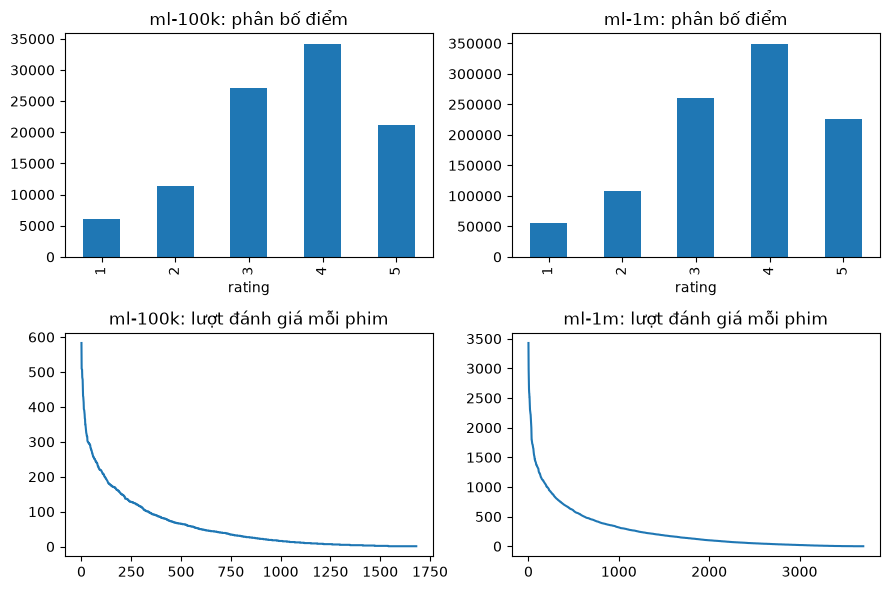

In [11]:
fig, axes = plt.subplots(2, len(names), figsize=(4.5 * len(names), 6), squeeze=False)
for j, n in enumerate(names):
    ratings, movies = recsys.load_cached(n)
    ratings.rating.value_counts().sort_index().plot.bar(ax=axes[0][j], title=f"{n}: phân bố điểm")
    ratings.groupby("item").size().sort_values(ascending=False).reset_index(drop=True).plot(
        ax=axes[1][j], title=f"{n}: lượt đánh giá mỗi phim")
plt.tight_layout(); plt.show()

## 2. Quy trình đánh giá
- **Chia dữ liệu 70% train / 10% validation / 20% test, riêng cho từng người dùng** (mỗi người đều có phim ở cả 3 tập, luôn giữ ≥ 5 phim trong train).
- **Lặp lại với nhiều seed** và báo cáo *trung bình ± độ lệch chuẩn* thay vì một lần chia.
- **Chọn K trên validation theo từng mục tiêu**: `ranking` (Precision@10 cao nhất – gợi ý danh sách phim, *mục tiêu chính của đề tài*) và `rating` (RMSE thấp nhất – dự đoán điểm). Sau đó huấn luyện lại trên train+validation và đánh giá test đúng một lần.
- KNN là thuật toán *lazy*: `fit` tính ma trận tương đồng, giữ K láng giềng gần nhất và tính sẵn điểm dự đoán. Không có epoch hay hàm loss.

In [12]:
n0 = names[0]
ratings, movies = recsys.load_cached(n0)
n_u, n_i = int(ratings.user.max()) + 1, len(movies)
train, val, test = recsys.split3(ratings, seed=SEEDS[0], per_user=PER_USER)
print(f"[{n0}] train={len(train):,} | validation={len(val):,} | test={len(test):,}")
print("Người dùng thiếu dữ liệu ở train / val / test:",
      n_u - train.user.nunique(), "/", n_u - val.user.nunique(), "/", n_u - test.user.nunique())
print("Số phim train ít nhất của một người dùng:", train.groupby("user").size().min())

t0 = time.time()
model = recsys.KNNRecommender(k=20, mode="item", shrink=SHRINK).fit(recsys.to_matrix(train, n_u, n_i))
print(f"Huấn luyện Item-KNN (K=20): {time.time()-t0:.2f}s | ma trận tương đồng {model.item_sim_.shape}")
print("Validation: MAE=%.4f RMSE=%.4f" % recsys.rating_metrics(model.P, val))

[ml-100k] train=70,012 | validation=9,988 | test=20,000
Người dùng thiếu dữ liệu ở train / val / test: 0 / 0 / 0
Số phim train ít nhất của một người dùng: 14
Huấn luyện Item-KNN (K=20): 0.42s | ma trận tương đồng (1682, 1682)
Validation: MAE=0.7622 RMSE=0.9842


## 3. Chọn K bằng validation và đánh giá cuối trên test
Bộ 1M × nhiều seed có thể mất vài phút. Muốn chạy nhanh khi thử, giảm `SEEDS` hoặc `KS` ở ô đầu.

In [13]:
final, curves, info = recsys.select_and_evaluate(names, ks=KS, shrink=SHRINK, topn=TOPN,
                                                 seeds=SEEDS, per_user=PER_USER, quiet=True)
display(info)

,dataset,users,movies,ratings,sparsity,ratings_per_user,ratings_per_movie,est_mem_gb
0,ml-100k,943,1682,100000,0.9370,106.0,59.5,0.08
1,ml-1m,6040,3883,1000209,0.9574,165.6,257.6,1.19


### Mục tiêu chính – gợi ý danh sách phim (K chọn theo Precision@10 trên validation)

In [14]:
COLS = ["P@10", "R@10", "test_RMSE", "test_MAE", "fit_sec"]
summ = recsys.summarize(final, ["dataset", "mode", "goal"], COLS)
summ[summ.goal.isin(["ranking", "baseline"])].sort_values(["dataset", "mode"])

,dataset,mode,goal,n_seeds,best_K (mỗi seed),P@10,R@10,test_RMSE,test_MAE,fit_sec
0,ml-100k,baseline,baseline,3,"0, 0, 0",0.1354 ± 0.0013,0.1373 ± 0.0019,1.024 ± 0.0018,0.8154 ± 0.0012,0.0 ± 0.0
1,ml-100k,item,ranking,3,"50, 20, 50",0.2021 ± 0.0034,0.2014 ± 0.0075,0.9384 ± 0.0143,0.7271 ± 0.0087,0.203 ± 0.1051
3,ml-100k,user,ranking,3,"50, 100, 50",0.222 ± 0.0014,0.2405 ± 0.0025,0.9505 ± 0.0126,0.7377 ± 0.0086,0.1659 ± 0.1595
5,ml-1m,baseline,baseline,3,"0, 0, 0",0.147 ± 0.0013,0.0869 ± 0.0015,0.9796 ± 0.0019,0.7824 ± 0.0014,0.0 ± 0.0
6,ml-1m,item,ranking,3,"50, 50, 50",0.2205 ± 0.0011,0.1438 ± 0.0013,0.8813 ± 0.0015,0.6836 ± 0.001,3.1846 ± 0.3279
8,ml-1m,user,ranking,3,"100, 100, 100",0.2295 ± 0.0014,0.1597 ± 0.0023,0.9061 ± 0.0015,0.7013 ± 0.0008,4.3679 ± 0.3346


### Mục tiêu phụ – dự đoán điểm đánh giá (K chọn theo RMSE trên validation)

In [15]:
summ[summ.goal.isin(["rating", "baseline"])].sort_values(["dataset", "mode"])

,dataset,mode,goal,n_seeds,best_K (mỗi seed),P@10,R@10,test_RMSE,test_MAE,fit_sec
0,ml-100k,baseline,baseline,3,"0, 0, 0",0.1354 ± 0.0013,0.1373 ± 0.0019,1.024 ± 0.0018,0.8154 ± 0.0012,0.0 ± 0.0
2,ml-100k,item,rating,3,"200, 200, 200",0.1905 ± 0.0051,0.1893 ± 0.0076,0.9117 ± 0.0026,0.7131 ± 0.0009,0.145 ± 0.0239
4,ml-100k,user,rating,3,"200, 200, 200",0.2111 ± 0.0028,0.2214 ± 0.0013,0.935 ± 0.0027,0.7288 ± 0.0017,0.0772 ± 0.008
5,ml-1m,baseline,baseline,3,"0, 0, 0",0.147 ± 0.0013,0.0869 ± 0.0015,0.9796 ± 0.0019,0.7824 ± 0.0014,0.0 ± 0.0
7,ml-1m,item,rating,3,"200, 200, 200",0.2107 ± 0.0013,0.1375 ± 0.0015,0.8668 ± 0.0011,0.6775 ± 0.0007,3.3225 ± 0.0988
9,ml-1m,user,rating,3,"200, 200, 200",0.2236 ± 0.0018,0.1521 ± 0.0025,0.8995 ± 0.0015,0.6977 ± 0.001,4.6593 ± 0.1534


Không có một cấu hình tốt nhất cho mọi mục tiêu: hãy đối chiếu cột `best_K` của hai bảng trên.

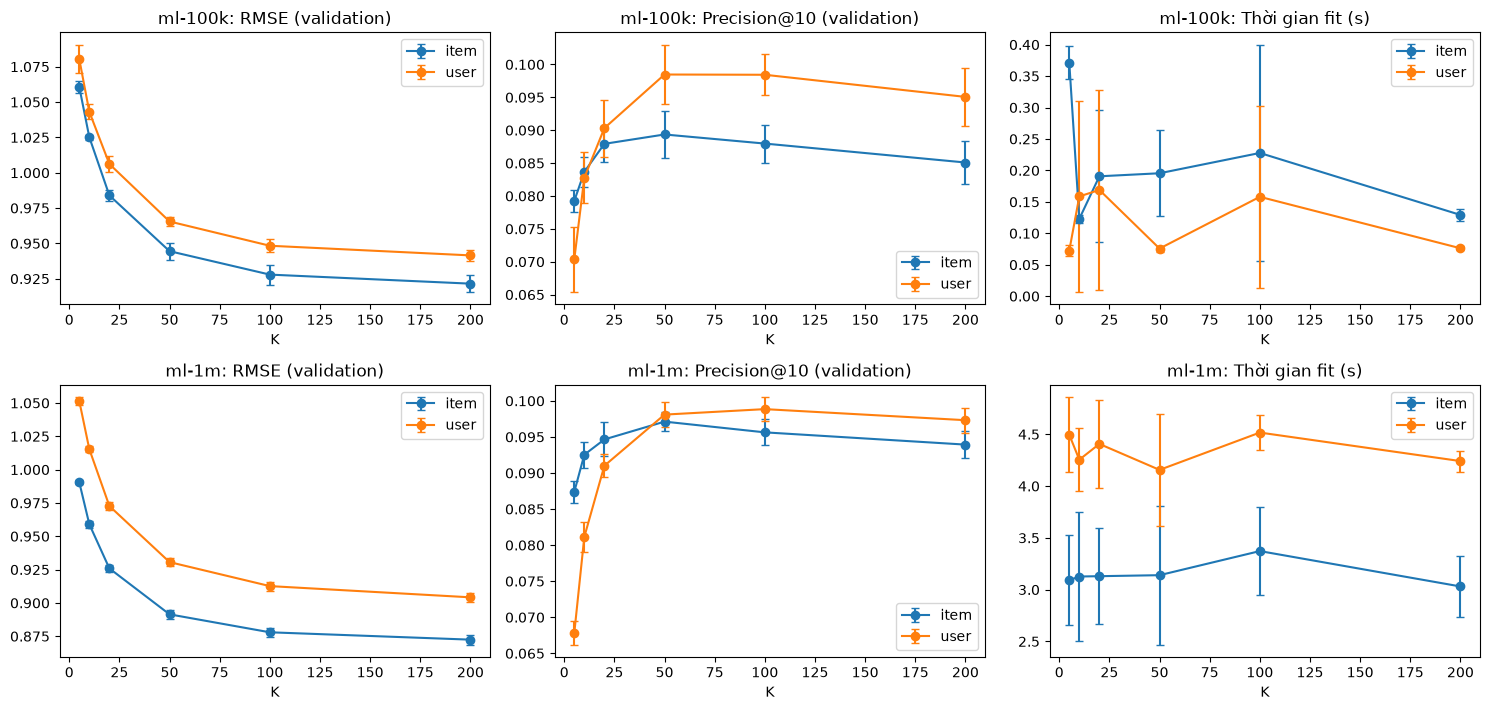

In [16]:
fig, axes = plt.subplots(len(names), 3, figsize=(15, 3.6 * len(names)), squeeze=False)
for row, (ds, g0) in zip(axes, curves.groupby("dataset", sort=False)):
    for mode, g in g0.groupby("mode"):
        agg = g.groupby("K")[["val_RMSE", "val_P@10", "fit_sec"]].agg(["mean", "std"]).fillna(0)
        for ax, col in zip(row, ["val_RMSE", "val_P@10", "fit_sec"]):
            ax.errorbar(agg.index, agg[col]["mean"], yerr=agg[col]["std"], marker="o", capsize=3, label=mode)
    for ax, t in zip(row, ["RMSE (validation)", "Precision@10 (validation)", "Thời gian fit (s)"]):
        ax.set_title(f"{ds}: {t}"); ax.set_xlabel("K"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Ảnh hưởng của shrinkage (K=20, item-based, đo trên validation)

In [17]:
abl = recsys.shrink_ablation(names, shrinks=[0, 10, 25, 50, 100, 200], k=20, seeds=SEEDS, per_user=PER_USER)
recsys.summarize(abl, ["dataset", "shrink"], ["val_RMSE", "val_P@10"])

,dataset,shrink,n_seeds,val_RMSE,val_P@10
0,ml-100k,0,3,1.0253 ± 0.0042,0.0737 ± 0.0014
1,ml-100k,10,3,0.984 ± 0.0041,0.0879 ± 0.0027
2,ml-100k,25,3,0.977 ± 0.0049,0.0896 ± 0.003
3,ml-100k,50,3,0.9735 ± 0.0037,0.0905 ± 0.003
4,ml-100k,100,3,0.9734 ± 0.0038,0.0913 ± 0.0043
5,ml-100k,200,3,0.9728 ± 0.004,0.0917 ± 0.0028
6,ml-1m,0,3,0.9442 ± 0.0015,0.0944 ± 0.0019
7,ml-1m,10,3,0.9259 ± 0.0024,0.0947 ± 0.0024
8,ml-1m,25,3,0.9208 ± 0.0025,0.0951 ± 0.0019
9,ml-1m,50,3,0.9184 ± 0.0028,0.0947 ± 0.0016


## 5. Ví dụ gợi ý

In [18]:
for n in names:
    ratings, movies = recsys.load_cached(n)
    n_u = int(ratings.user.max()) + 1
    model = recsys.KNNRecommender(50, "item", shrink=SHRINK).fit(recsys.to_matrix(ratings, n_u, len(movies)))
    idx, pred = model.recommend(0, 5)
    print(f"=== {n}: gợi ý cho user đầu tiên ===")
    display(movies.loc[idx, ["title", "genres"]].assign(pred=pred.round(2)))
    hit = movies.index[movies.title.str.contains("Toy Story", regex=False)]
    if len(hit):
        idx, sim = model.similar_items(hit[0], 5)
        print("Phim giống:", movies.title[hit[0]])
        display(movies.loc[idx, ["title", "genres"]].assign(sim=sim.round(3)))
        # người dùng mới: chỉ cần chấm vài phim
        idx, pred, sc = model.recommend_for_ratings({hit[0]: 5}, 5)
        print("Người dùng mới chỉ chấm 5★ cho Toy Story ->"); display(movies.loc[idx, ["title"]].assign(pred=pred.round(2)))

=== ml-100k: gợi ý cho user đầu tiên ===


,title,genres,pred
317,Schindler's List (1993),Drama|War,4.90
356,One Flew Over the Cuckoo's Nest (1975),Drama,4.58
650,Glory (1989),Action|Drama|War,4.30
482,Casablanca (1942),Drama|Romance|War,4.82
479,North by Northwest (1959),Comedy|Thriller,4.57


Phim giống: Toy Story (1995)


,title,genres,sim
173,Raiders of the Lost Ark (1981),Action|Adventure,0.262
49,Star Wars (1977),Action|Adventure|Romance|Sci-Fi|War,0.229
587,Beauty and the Beast (1991),Animation|Children's|Musical,0.227
27,Apollo 13 (1995),Action|Drama|Thriller,0.218
94,Aladdin (1992),Animation|Children's|Comedy|Musical,0.205


Người dùng mới chỉ chấm 5★ cho Toy Story ->


,title,pred
173,Raiders of the Lost Ark (1981),5.00
49,Star Wars (1977),5.00
587,Beauty and the Beast (1991),4.91
27,Apollo 13 (1995),5.00
94,Aladdin (1992),4.93


... (2 outputs left out)

Phim giống: Toy Story (1995)


,title,genres,sim
3045,Toy Story 2 (1999),Animation|Children's|Comedy,0.498
1180,Raiders of the Lost Ark (1981),Action|Adventure,0.308
2286,"Bug's Life, A (1998)",Animation|Children's|Comedy,0.299
315,"Shawshank Redemption, The (1994)",Drama,0.285
1178,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War,0.284


Người dùng mới chỉ chấm 5★ cho Toy Story ->


,title,pred
3045,Toy Story 2 (1999),5.00
1180,Raiders of the Lost Ark (1981),5.00
2286,"Bug's Life, A (1998)",4.71
315,"Shawshank Redemption, The (1994)",5.00
1178,Star Wars: Episode V - The Empire Strikes Back...,5.00


## 6. Phân tích & kết luận (đối chiếu với các bảng ở trên)
**Chọn cấu hình theo mục tiêu.** Mục tiêu chính là gợi ý danh sách phim, nên chọn K theo Precision@10/Recall@10 và coi RMSE/MAE là chỉ số bổ sung. K tối ưu cho hai mục tiêu thường khác nhau (RMSE ưa K lớn vì làm mịn dự đoán; xếp hạng top-N thường đạt đỉnh ở K trung bình) – ghi `best_K` cụ thể từ hai bảng.

**Độ tin cậy.** Chỉ coi một chênh lệch là có ý nghĩa khi lớn hơn độ lệch chuẩn giữa các seed. Các chênh lệch nhỏ (ví dụ User-KNN vs Item-KNN ở Precision@10) cần đối chiếu với cột `± std`.

**So sánh giữa các bộ dữ liệu.** Không mặc định bộ lớn hơn cho kết quả tốt hơn ở mọi chỉ số: bộ 1M *thưa hơn* 100K (≈95.7% so với ≈93.7%) nhưng có nhiều lượt đánh giá hơn trên mỗi phim/người dùng (xem `ratings_per_movie`, `ratings_per_user` ở bảng thông tin). Hãy so sánh từng chỉ số riêng; Recall@10 còn phụ thuộc số phim liên quan của mỗi người dùng nên không so trực tiếp giữa các bộ được.

**Ưu điểm:** dễ hiểu, giải thích được ("giống phim X bạn đã thích"), item-based ổn định, không cần huấn luyện phức tạp.

**Hạn chế:** dữ liệu thưa, cold-start (người dùng/phim mới, xem `recommend_for_ratings` cho người dùng mới), thiên lệch phổ biến, và bộ nhớ O(n²) cho ma trận tương đồng – `est_mem_gb` ở bảng thông tin cho thấy ml-10m/25m cần hàng chục đến hàng trăm GB nên bị chặn (`MAX_GB`).

**Ảnh hưởng của K:** K nhỏ → nhiễu; K lớn → làm mịn quá mức, kéo dự đoán về trung bình. Thời gian fit gần như không đổi theo K vì phần tốn nhất là tính ma trận tương đồng.

**Cách cải thiện:** shrinkage (đã dùng), content-based (thể loại), matrix factorization, ANN (FAISS), ma trận thưa, chia theo thời gian.